In [1]:
from maxent_insect_dir import config
import pathlib
import geopandas as gpd
import rasterio.plot as rioplot # To Visualize Raster Data
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import os


pd.options.mode.chained_assignment = None  # default='warn'

In [2]:
config.Insect_list

{'Brown_Marmorated_Stink_bug': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Brown_Marmorated_Stink_Bug - (Halyomorpha_halys) (1999_2023).gpkg'),
 'Corn_Earworm': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Corn_Earworm - (Helicoverpa_Zea) (2004-2023).gpkg'),
 'Large_Lady_Beetle': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/EDD Maps Site/Large_Lady_Beetle - (Harmonia_Axyridis) (1995-2023).gpkg'),
 'Brown_Marmorated_Stink_bug_2': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/GBIF Site/Brown_Marmorated_Stink_Bug -  (Halyomorpha_halys) (2007-2023).gpkg'),
 'Root_Weevil': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/Species Data/Guna/GBIF Site/Root_Weevil - (Diaprepes_abbreviatus) (2012-2023).gpkg')}

In [3]:
INSECT_NAME = 'Brown_Marmorated_Stink_bug'
INSECT_DATA = config.config_['insect']['EDD'][INSECT_NAME]
PATH_SAVE_FIG = config.PATH_TO_SAVE_INITIAL_DATA_VIS_INSECT

# Load the data

In [4]:
# Define function to read GeoDataFrame with exception handling
def safe_read_file(file_path, layer_name=None):
    try:
        if layer_name:
            return gpd.read_file(file_path, layer=layer_name)
        else:
            return gpd.read_file(file_path)
    except UnicodeDecodeError:
        print(f"Unicode decoding error occurred while reading layer '{layer_name}' from {file_path}. Attempting with ISO-8859-1 encoding.")
        try:
            if layer_name:
                return gpd.read_file(file_path, layer=layer_name, encoding='ISO-8859-1')
            else:
                return gpd.read_file(file_path, encoding='ISO-8859-1')
        except Exception as e:
            print(f"Failed to read layer '{layer_name}' from {file_path}: {e}")
            return None
    except Exception as e:
        print(f"An error occurred while reading layer '{layer_name}' from {file_path}: {e}")
        return None

In [5]:
# Load the presence data
presence = safe_read_file(INSECT_DATA)

/home/pc19d/anaconda3/envs/postdoc/lib/python3.12/site-packages/pyogrio/geopandas.py:261: UserWarning: More than one layer found in 'Brown_Marmorated_Stink_Bug - (Halyomorpha_halys) (1999_2023).gpkg': 'PointLayer' (default), 'PolygonLayer', 'LineLayer'. Specify layer parameter to avoid this warning.
  result = read_func(


Without passing the layer default parameter, the code is throwing some error. I don't know exactly what layer means, but i guess its how they define the geometry of an area. ChatGPT says:

-   PointLayer (default): Contains point geometries, which represent individual locations, like a single coordinate (e.g., the location of a specific bug sighting).

-   PolygonLayer: Contains polygon geometries, which represent areas or boundaries, like the geographic boundary of a region where the bug is found.

-   LineLayer: Contains line geometries, which represent linear features, like roads or paths where the bug might be observed.

The warning suggests specifying which layer you want to work with when reading the file to avoid any ambiguity. By default, PointLayer is selected, but you can choose another layer by using the layer parameter in your code.


In [6]:
# Load the presence data layerwise
presence_PointLayer = safe_read_file(INSECT_DATA, layer_name = 'PointLayer')

presence_PolygonLayer = safe_read_file(INSECT_DATA, layer_name = 'PolygonLayer')

presence_LineLayer = safe_read_file(INSECT_DATA, layer_name = 'LineLayer')

In [7]:
# all of them have different shape. Majority of data is pointlayer
presence_PolygonLayer.shape, presence_PointLayer.shape, presence_LineLayer.shape

((2, 80), (13797, 80), (5, 80))

In [8]:
presence_PolygonLayer

,objectid,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,...,Reference,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm,geometry
0,4873469,Christine Price,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,03-15-17,03-15-17,...,None,"""Greenwich""","""Started 2015 Winter is less. THey are all ove...",11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...","MULTIPOLYGON (((-73.63325 41.26834, -73.6323 4..."
1,5159667,Lynne Fabricant,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,09-03-17,09-05-17,...,None,"""3859 Vine Maple Street, Eugene,""","""significant damage to jalapeno fruits in home...",09-06-17,David Lowenstein,Photographs,Verified,Verified,"""damage to peppers""","MULTIPOLYGON (((-123.06535 44.01346, -123.0653..."


In [9]:
presence_LineLayer

,objectid,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,...,Reference,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm,geometry
0,4867422,Joann Devine,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,03-06-17,03-06-17,...,None,None,None,11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...","MULTILINESTRING ((-74.04022 41.58809, -74.0401..."
1,4875469,Gail Earl,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,03-01-17,03-19-17,...,None,None,None,11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...","MULTILINESTRING ((-73.97985 42.6129, -73.97978..."
2,5167886,Steve Mastrandrea,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,09-28-17,09-28-17,...,None,None,None,10-02-17,David Lowenstein,Expertise,Verified,Verified,"""""","MULTILINESTRING ((-122.66758 45.36784, -122.66..."
3,5177562,Steve Mastrandrea,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,10-04-17,10-04-17,...,None,"""21630 S. Sweetbriar Circle, West Linn, OR 97068""",None,10-05-17,George Hamilton,Photographs,Verified,Verified,"""""","MULTILINESTRING ((-122.66736 45.36777, -122.66..."
4,7795935,Jesse Clark,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,08-21-18,08-21-18,...,None,"""Aloha, OR""",None,08-30-18,David Lowenstein,Photographs,Verified,Verified,"""""","MULTILINESTRING ((-122.88316 45.49665, -122.88..."


In [10]:
# Double checking that Presence data is equal to presence_PointLayer
presence.equals(presence_PointLayer)

True

In [11]:
presence_PointLayer.columns

Index(['objectid', 'reporter', 'RecOwner', 'SciName', 'ComName', 'Nativity',
       'OccStatus', 'Status', 'ObsDate', 'DateEnt', 'DateUp', 'Location',
       'Latitude', 'Longitude', 'Datum', 'Method', 'CoordAcc', 'DataType',
       'Centroid', 'Abundance', 'InfestAcre', 'GrossAcre', 'Percentcov',
       'Density', 'Quantity', 'QuantityU', 'APPXQuant', 'NumCollect',
       'Smallest', 'Largest', 'Incidence', 'Severity', 'Host', 'Host_Name',
       'HostPheno', 'HostDamage', 'ManageStat', 'PopStat', 'Habitat',
       'LocalOwner', 'Site', 'RecBasis', 'Museum', 'MuseumRec', 'Voucher',
       'ObsIDer', 'CollectTme', 'UUID', 'OrgSrcID', 'OrigName', 'RecSrcTyp',
       'Surveyor', 'DateAcc', 'VisitType', 'DataMthd', 'TrapType', 'NumTraps',
       'TargetName', 'TargetCnt', 'TargetRnge', 'Phenology', 'LifeStatus',
       'Sex', 'PID', 'WaterName', 'WaterType', 'Substrate', 'TreatArea',
       'PlantTreat', 'TreatComm', 'Reference', 'Locality', 'Comments',
       'ReviewDate', 'Reviewer', 'V

In [12]:
presence.describe(include='object')

,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,DateUp,...,TreatComm,Reference,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm
count,13797,13797,13797,13797,13797,13797,13797,13797,13797,1126,...,84,844,1352,1877,2725,2725,2926,13797,13096,2636
unique,931,14,1,1,1,2,2,3455,773,668,...,1,17,636,1279,493,36,11,2,8,297
top,Rutgers Stink Bug Reports Rutgers,University,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,10-25-07,07-24-13,10-01-15,...,"""""","""iNaturalist.org (2018). iNaturalist Research-...","""House""","""""",03-23-18,Angie Ambourn,Bulk Verified,Verified,Unconfirmed,""""""
freq,10379,11182,13797,13797,13797,13785,13785,100,10585,26,...,84,571,232,308,292,1022,1997,13792,8322,931


In [13]:
presence.describe(include='object')

,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,DateUp,...,TreatComm,Reference,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm
count,13797,13797,13797,13797,13797,13797,13797,13797,13797,1126,...,84,844,1352,1877,2725,2725,2926,13797,13096,2636
unique,931,14,1,1,1,2,2,3455,773,668,...,1,17,636,1279,493,36,11,2,8,297
top,Rutgers Stink Bug Reports Rutgers,University,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,10-25-07,07-24-13,10-01-15,...,"""""","""iNaturalist.org (2018). iNaturalist Research-...","""House""","""""",03-23-18,Angie Ambourn,Bulk Verified,Verified,Unconfirmed,""""""
freq,10379,11182,13797,13797,13797,13785,13785,100,10585,26,...,84,571,232,308,292,1022,1997,13792,8322,931


In [14]:
# Here basically points means the longitude and latitudes
presence_PointLayer[['ObsDate','DateEnt','OccStatus','NumCollect','Latitude','Longitude','geometry']]

,ObsDate,DateEnt,OccStatus,NumCollect,Latitude,Longitude,geometry
0,04-11-11,01-11-12,Detected,None,41.96179,-74.28114,POINT (-74.28114 41.96179)
1,04-11-11,01-11-12,Detected,None,42.07733,-74.10828,POINT (-74.10828 42.07733)
2,04-21-12,05-23-12,Detected,None,41.63886,-73.92247,POINT (-73.92247 41.63886)
3,05-13-12,05-23-12,Detected,None,41.63883,-73.92251,POINT (-73.92251 41.63883)
4,05-07-12,05-23-12,Detected,None,41.63884,-73.92287,POINT (-73.92287 41.63884)
...,...,...,...,...,...,...,...
13792,04-14-23,04-14-23,Detected,None,44.80858,-93.15730,POINT (-93.1573 44.80858)
13793,04-14-23,04-14-23,Detected,None,44.93518,-93.23176,POINT (-93.23176 44.93518)
13794,04-14-23,04-14-23,Detected,None,44.94636,-93.29502,POINT (-93.29502 44.94636)
13795,04-14-23,04-14-23,Detected,None,45.12412,-93.27460,POINT (-93.2746 45.12412)


In [15]:
# Check if we have count data, i.e Number of count observed at a location.
presence_PointLayer[['NumCollect']].value_counts()

NumCollect
1             282
5              74
2              58
3              25
10             19
             ... 
90              1
95              1
900             1
Many            1
few             1
Name: count, Length: 82, dtype: int64

In [16]:
# OccStatus should have two label -- Detected and Undetected. Most of the data is presence only data, i.e we only have sample where the species is found.
presence_PointLayer[['OccStatus']].value_counts()

OccStatus 
Detected      13785
Undetected       12
Name: count, dtype: int64

In [17]:
# Let keep the data tha we are interested in.
presence_PointLayer_trimmed =  presence_PointLayer[['ObsDate','DateEnt','OccStatus','NumCollect','Latitude','Longitude','geometry']]

# Add explicit label to the data
label = presence_PointLayer_trimmed['OccStatus'].apply(lambda x: 1 if x.lower() == "detected" else 0)
presence_PointLayer_trimmed['label'] = label

# Clean the NumCollect data, adding 1 to each entry -- There's an entry many here, i am replacing it by 1, because many is ambiguous. 
NumCollect_int  = presence_PointLayer_trimmed['NumCollect'].apply(lambda x: 1 + 1 if isinstance(x,int) == True else 1)
presence_PointLayer_trimmed['NumCollect_int'] = NumCollect_int

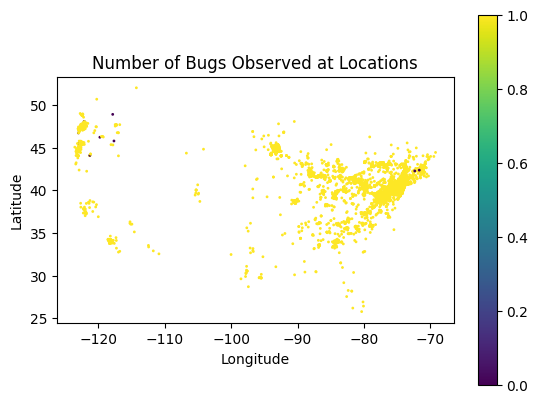

In [19]:
# Plot the points, with size corresponding to the number of bugs observed
presence_PointLayer_trimmed.plot(marker='o', column='label', markersize=presence_PointLayer_trimmed['NumCollect_int'], cmap='viridis', legend=True)
plt.title("Number of Bugs Observed at Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
# plt.savefig(os.path.join(PATH_SAVE_FIG, INSECT_NAME + '_map.png'))
plt.show()

In [20]:
# Convert 'ObsDate' to datetime format
presence_PointLayer_trimmed['ObsDate'] = pd.to_datetime(presence_PointLayer_trimmed['ObsDate'], format='%m-%d-%y')
presence_PointLayer_trimmed 

,ObsDate,DateEnt,OccStatus,NumCollect,Latitude,Longitude,geometry,label,NumCollect_int
0,2011-04-11,01-11-12,Detected,None,41.96179,-74.28114,POINT (-74.28114 41.96179),1,1
1,2011-04-11,01-11-12,Detected,None,42.07733,-74.10828,POINT (-74.10828 42.07733),1,1
2,2012-04-21,05-23-12,Detected,None,41.63886,-73.92247,POINT (-73.92247 41.63886),1,1
3,2012-05-13,05-23-12,Detected,None,41.63883,-73.92251,POINT (-73.92251 41.63883),1,1
4,2012-05-07,05-23-12,Detected,None,41.63884,-73.92287,POINT (-73.92287 41.63884),1,1
...,...,...,...,...,...,...,...,...,...
13792,2023-04-14,04-14-23,Detected,None,44.80858,-93.15730,POINT (-93.1573 44.80858),1,1
13793,2023-04-14,04-14-23,Detected,None,44.93518,-93.23176,POINT (-93.23176 44.93518),1,1
13794,2023-04-14,04-14-23,Detected,None,44.94636,-93.29502,POINT (-93.29502 44.94636),1,1
13795,2023-04-14,04-14-23,Detected,None,45.12412,-93.27460,POINT (-93.2746 45.12412),1,1


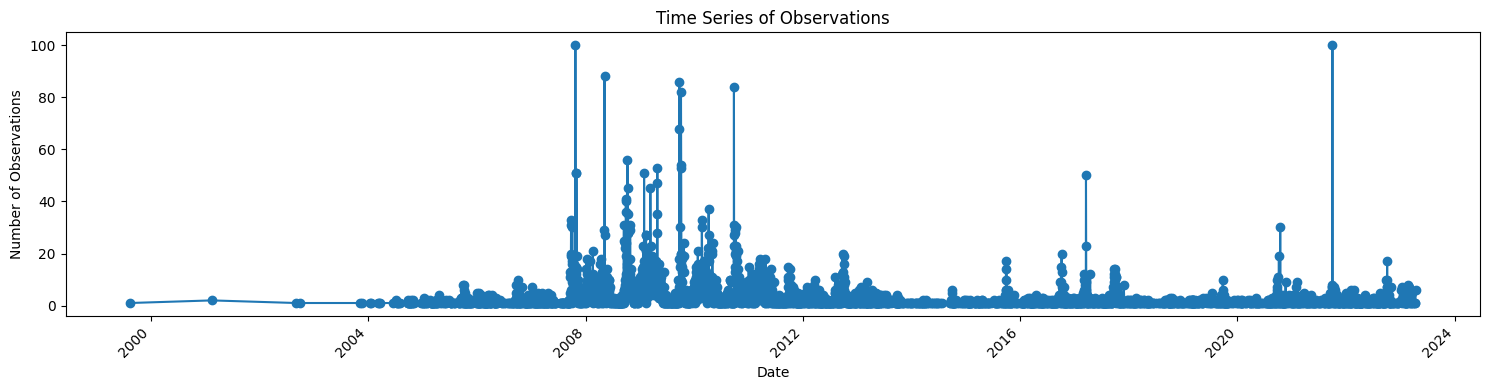

In [21]:
# Plotting a time series plot
plt.figure(figsize=(15, 4))

presence_PointLayer_trimmed.groupby('ObsDate').size().sort_index().plot(kind='line', marker='o')

plt.title('Time Series of Observations')
plt.xlabel('Date')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45)
plt.tight_layout()
# plt.savefig(os.path.join(PATH_SAVE_FIG, INSECT_NAME + '_timeline.png'))
plt.show()

In [25]:
presence_PointLayer_trimmed.to_file('output_file.gpkg', driver='GPKG', layer='PointLayer')

In [26]:
gpd.read_file('output_file.gpkg', layer='PointLayer')

,ObsDate,DateEnt,OccStatus,NumCollect,Latitude,Longitude,label,NumCollect_int,geometry
0,2011-04-11,01-11-12,Detected,None,41.96179,-74.28114,1,1,POINT (-74.28114 41.96179)
1,2011-04-11,01-11-12,Detected,None,42.07733,-74.10828,1,1,POINT (-74.10828 42.07733)
2,2012-04-21,05-23-12,Detected,None,41.63886,-73.92247,1,1,POINT (-73.92247 41.63886)
3,2012-05-13,05-23-12,Detected,None,41.63883,-73.92251,1,1,POINT (-73.92251 41.63883)
4,2012-05-07,05-23-12,Detected,None,41.63884,-73.92287,1,1,POINT (-73.92287 41.63884)
...,...,...,...,...,...,...,...,...,...
13792,2023-04-14,04-14-23,Detected,None,44.80858,-93.15730,1,1,POINT (-93.1573 44.80858)
13793,2023-04-14,04-14-23,Detected,None,44.93518,-93.23176,1,1,POINT (-93.23176 44.93518)
13794,2023-04-14,04-14-23,Detected,None,44.94636,-93.29502,1,1,POINT (-93.29502 44.94636)
13795,2023-04-14,04-14-23,Detected,None,45.12412,-93.27460,1,1,POINT (-93.2746 45.12412)
